In [79]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import numpy as np


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier


In [60]:
from sklearn.metrics import (accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay)

In [127]:
# df_test=pd.read_csv("test_Y3wMUE5_7gLdaTN.csv")
df_train=pd.read_csv("train_u6lujuX_CVtuZ9i.csv")

In [128]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [129]:
df_train=df_train.dropna(subset=['Gender','Dependents','Self_Employed','Loan_Amount_Term','Credit_History','LoanAmount'])

In [130]:
df_train.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [131]:
df_train=df_train.drop(columns=['Loan_ID'])

In [132]:
df_train

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [133]:
categorical_cols = ['Gender', 'Married', 'Dependents',
                    'Education', 'Self_Employed', 'Property_Area','Loan_Status']

df_train = pd.get_dummies(df_train, columns=categorical_cols, dtype=int)

In [134]:
df_train.columns

Index(['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Gender_Female', 'Gender_Male',
       'Married_No', 'Married_Yes', 'Dependents_0', 'Dependents_1',
       'Dependents_2', 'Dependents_3+', 'Education_Graduate',
       'Education_Not Graduate', 'Self_Employed_No', 'Self_Employed_Yes',
       'Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban',
       'Loan_Status_N', 'Loan_Status_Y'],
      dtype='object')

In [135]:
df_train.drop(columns=['Gender_Female','Married_No','Dependents_0','Education_Not Graduate','Self_Employed_No','Property_Area_Urban','Loan_Status_N'],inplace=True)

In [136]:
df_train.head(4)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Loan_Status_Y
1,4583,1508.0,128.0,360.0,1.0,1,1,1,0,0,1,0,1,0,0
2,3000,0.0,66.0,360.0,1.0,1,1,0,0,0,1,1,0,0,1
3,2583,2358.0,120.0,360.0,1.0,1,1,0,0,0,0,0,0,0,1
4,6000,0.0,141.0,360.0,1.0,1,0,0,0,0,1,0,0,0,1


<Axes: ylabel='CoapplicantIncome'>

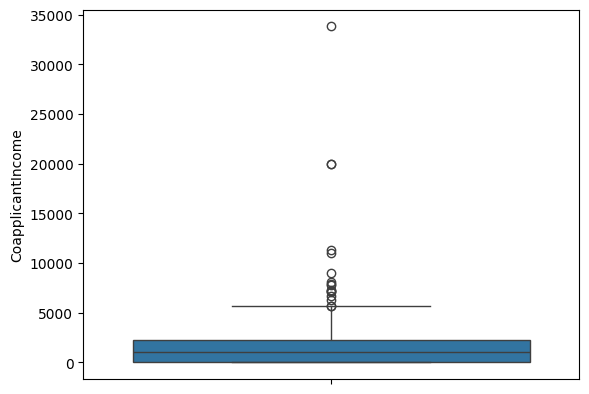

In [112]:
sns.boxplot(df_train['CoapplicantIncome'])

<Axes: ylabel='ApplicantIncome'>

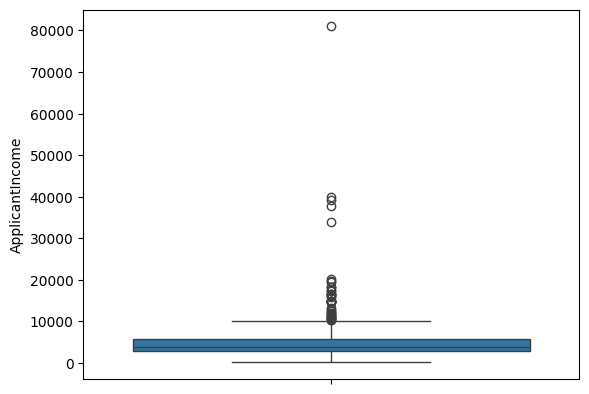

In [113]:
sns.boxplot(df_train['ApplicantIncome'])

<Axes: ylabel='LoanAmount'>

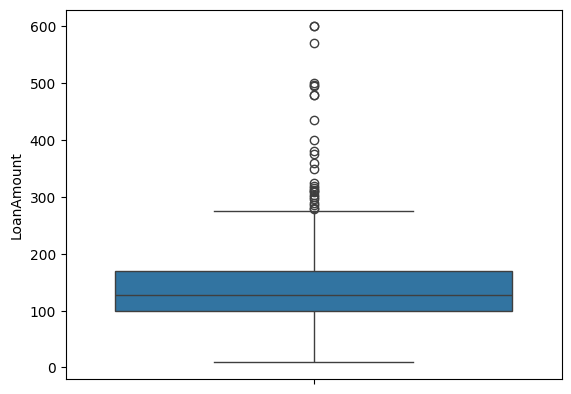

In [114]:
sns.boxplot(df_train['LoanAmount'])

In [115]:
print(df_train['ApplicantIncome'].skew())

df_train['ApplicantIncome'] = np.log1p(df_train['ApplicantIncome'])

print(df_train['ApplicantIncome'].skew())

6.917026514199138
0.5651441603527614


In [116]:
print(df_train['CoapplicantIncome'].skew())

df_train['CoapplicantIncome'] = np.log1p(df_train['CoapplicantIncome'])

print(df_train['CoapplicantIncome'].skew())

5.881622127841592
-0.15010350243127799


In [117]:
print(df_train['LoanAmount'].skew())

df_train['LoanAmount'] = np.log1p(df_train['LoanAmount'])

print(df_train['LoanAmount'].skew())

2.3614368477871213
-0.3755444512878643


In [137]:
df_train['Loan_Amount_Term']=df_train['Loan_Amount_Term']/12

In [138]:
df_train

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Loan_Status_Y
1,4583,1508.0,128.0,30.0,1.0,1,1,1,0,0,1,0,1,0,0
2,3000,0.0,66.0,30.0,1.0,1,1,0,0,0,1,1,0,0,1
3,2583,2358.0,120.0,30.0,1.0,1,1,0,0,0,0,0,0,0,1
4,6000,0.0,141.0,30.0,1.0,1,0,0,0,0,1,0,0,0,1
5,5417,4196.0,267.0,30.0,1.0,1,1,0,1,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900,0.0,71.0,30.0,1.0,0,0,0,0,0,1,0,1,0,1
610,4106,0.0,40.0,15.0,1.0,1,1,0,0,1,1,0,1,0,1
611,8072,240.0,253.0,30.0,1.0,1,1,1,0,0,1,0,0,0,1
612,7583,0.0,187.0,30.0,1.0,1,1,0,1,0,1,0,0,0,1


In [139]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 480 entries, 1 to 613
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ApplicantIncome          480 non-null    int64  
 1   CoapplicantIncome        480 non-null    float64
 2   LoanAmount               480 non-null    float64
 3   Loan_Amount_Term         480 non-null    float64
 4   Credit_History           480 non-null    float64
 5   Gender_Male              480 non-null    int64  
 6   Married_Yes              480 non-null    int64  
 7   Dependents_1             480 non-null    int64  
 8   Dependents_2             480 non-null    int64  
 9   Dependents_3+            480 non-null    int64  
 10  Education_Graduate       480 non-null    int64  
 11  Self_Employed_Yes        480 non-null    int64  
 12  Property_Area_Rural      480 non-null    int64  
 13  Property_Area_Semiurban  480 non-null    int64  
 14  Loan_Status_Y            480 no

In [140]:
x=df_train.drop(columns=['Loan_Status_Y'])
y=df_train['Loan_Status_Y']

In [141]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [147]:
lr = LogisticRegression(max_iter=1000)
dt = DecisionTreeClassifier()
rf = RandomForestClassifier()
svm = SVC()

lr.fit(x_train, y_train)
dt.fit(x_train, y_train)
rf.fit(x_train, y_train)
svm.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


SVC()

In [149]:
lr_pred = lr.predict(x_test)
dt_pred = dt.predict(x_test)
rf_pred = rf.predict(x_test)
svm_pred = svm.predict(x_test)

In [151]:
predictions = {
    'Logistic Regression': lr_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'SVM': svm_pred
}

results = []

for name, pred in predictions.items():
    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.823,0.800,1.000,0.889
1,Decision Tree,0.719,0.825,0.765,0.794
2,Random Forest,0.812,0.805,0.971,0.880
3,SVM,0.708,0.708,1.000,0.829


In [152]:
results_df = results_df.sort_values('F1 Score', ascending=False)

print(results_df.round(3))

best_name = results_df.iloc[0]['Model']
best_pred = predictions[best_name]

print("Best Model:", best_name)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.823      0.800   1.000     0.889
2        Random Forest     0.812      0.805   0.971     0.880
3                  SVM     0.708      0.708   1.000     0.829
1        Decision Tree     0.719      0.825   0.765     0.794
Best Model: Logistic Regression


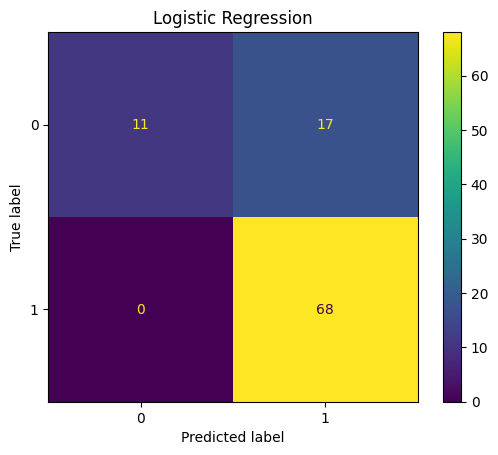

In [153]:
ConfusionMatrixDisplay.from_predictions(y_test, best_pred)

plt.title(best_name)
plt.show()

In [154]:
from sklearn.metrics import classification_report

print(classification_report(y_test, best_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.39      0.56        28
           1       0.80      1.00      0.89        68

    accuracy                           0.82        96
   macro avg       0.90      0.70      0.73        96
weighted avg       0.86      0.82      0.79        96



In [155]:
best = results_df.iloc[0]

print(f"{best_name} achieved the highest F1-score of {best['F1 Score']:.3f}.")
print(f"I selected this model because it balances precision and recall, with an accuracy of {best['Accuracy']:.3f}.")

Logistic Regression achieved the highest F1-score of 0.889.
I selected this model because it balances precision and recall, with an accuracy of 0.823.
